<a href="https://colab.research.google.com/github/Luis1941905/ISSD_PH/blob/main/Gonzalez_Luis_PH_TP1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP1 PROCESAMIENTO DEL HABLA: webscrapping

**Crea una copia de este notebook en tu google colab**

**Renombra el notebook con el siguiente formato APELLIDO_NOMBRE_PH_TP1.ipynb**

**[Escriba aquí su nombre completo.]**


* Resolver las consignas comentando el código fuente, indicando desde dónde fue extraido o generado.

* Explicar y justificar cada paso realizado usando los bloques de texto.

* Publique enlace público a su notebook en google colab y también enlace a su repositorio github de la materia.


## EJERCICIO CONSIGNA

* Cree una nube de palabras de un texto en español.

* Dicho texto puede ser descargado de Internet (webscrapping) o extraído del dataset de alguna librería.

* Puede usar cualquier libreria o herramienta para obtener el texto de su interés.

* En este notebook explica el paso a paso del proceso.



## 1- Webscrapping

Extrae un texto de Internet de una sóla página web usando alguna de las técnicas de webscrapping vistas en clase. Busca el discurso de alguna persona quien te inspire o haya dado una charla motivadora.

No puedes repetir ni usar ni el mismo texto ni la misma web que otra persona quien ya entregó en el foro.

Abajo añade los bloques de código y texto necesarios. Explica paso a paso como descargaste el texto de tu interés.


In [ ]:
# ======================================
# WEB SCRAPING DE UN DISCURSO MOTIVADOR
# J.K. Rowling - Harvard Commencement Speech
# ======================================

import requests
from bs4 import BeautifulSoup

# URL de la página
url = "https://news.harvard.edu/gazette/story/2008/06/text-of-j-k-rowling-speech/"

# Encabezados para simular un navegador
headers = {
    "User-Agent": "Mozilla/5.0"
}

# Descargar la página
respuesta = requests.get(url, headers=headers)

print(f"Código de estado: {respuesta.status_code}")

# Procesar el HTML
soup = BeautifulSoup(respuesta.text, "html.parser")

# Buscar todos los párrafos
parrafos = soup.find_all("p")

# Lista para almacenar el texto
discurso = []

for p in parrafos:
    texto = p.get_text(strip=True)

    if len(texto) > 20:
        discurso.append(texto)

# Guardar el texto extraído
with open("discurso_jk_rowling.txt", "w", encoding="utf-8") as archivo:
    for linea in discurso:
        archivo.write(linea + "\n")

print("Archivo generado correctamente.")

# Mostrar resultados
print(f"\nTotal de párrafos extraídos: {len(discurso)}")

print("\nPRIMEROS PÁRRAFOS EXTRAÍDOS:\n")

for texto in discurso[:10]:
    print(texto)
    print()

Código de estado: 200
Archivo generado correctamente.

Total de párrafos extraídos: 56

PRIMEROS PÁRRAFOS EXTRAÍDOS:

A series of random questions answered by Harvard experts.

J.K. Rowling acknowledges applause following the awarding of her honorary degree.

Jon Chase/Harvard Staff Photographer

Copyright J.K. Rowling

President Faust, members of the Harvard Corporation and the Board of Overseers, members of the faculty, proud parents, and, above all, graduates.

The first thing I would like to say is ‘thank you.’ Not only has Harvard given me an extraordinary honour, but the weeks of fear and nausea I have endured at the thought of giving this commencement address have made me lose weight. A win-win situation! Now all I have to do is take deep breaths, squint at the red banners and convince myself that I am at the world’s largest Gryffindor reunion.

Delivering a commencement address is a great responsibility; or so I thought until I cast my mind back to my own graduation. The commen

## 2- Preprocesamiento

### 2.1 Muestra las stop words que tenga tu texto.

In [ ]:
# Instalar recursos de NLTK (solo la primera vez)
import nltk

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Leer el archivo generado por el scraping
with open("discurso_jk_rowling.txt", "r", encoding="utf-8") as archivo:
    texto = archivo.read()

# Tokenizar el texto
palabras = word_tokenize(texto.lower())

# Stop words en inglés (porque el discurso está en inglés)
stop_words = set(stopwords.words('english'))

# Obtener las stop words presentes en el texto
stopwords_encontradas = sorted(set([
    palabra for palabra in palabras
    if palabra.isalpha() and palabra in stop_words
]))

print(f"Cantidad de stop words distintas encontradas: {len(stopwords_encontradas)}")
print("\nStop words encontradas:\n")
print(stopwords_encontradas)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Cantidad de stop words distintas encontradas: 110

Stop words encontradas:

['a', 'about', 'above', 'after', 'again', 'against', 'all', 'am', 'an', 'and', 'any', 'are', 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'between', 'both', 'but', 'by', 'can', 'did', 'do', 'does', 'down', 'during', 'for', 'from', 'had', 'has', 'have', 'having', 'he', 'her', 'here', 'him', 'his', 'how', 'i', 'if', 'in', 'into', 'is', 'it', 'its', 'itself', 'just', 'me', 'more', 'most', 'my', 'myself', 'no', 'not', 'now', 'of', 'off', 'on', 'only', 'or', 'other', 'our', 'ourselves', 'out', 'own', 's', 'she', 'should', 'so', 'some', 'such', 't', 'than', 'that', 'the', 'their', 'them', 'themselves', 'then', 'there', 'these', 'they', 'this', 'those', 'through', 'to', 'too', 'until', 'up', 've', 'very', 'was', 'we', 'were', 'what', 'when', 'where', 'which', 'who', 'whom', 'why', 'will', 'with', 'won', 'you', 'your', 'yourself']


### 2.2 Quita las stop-words, caracteres extraños del texto. Utiliza el texto restante para crear una nube de palabras. Usa la biblioteca worldcloud de python.

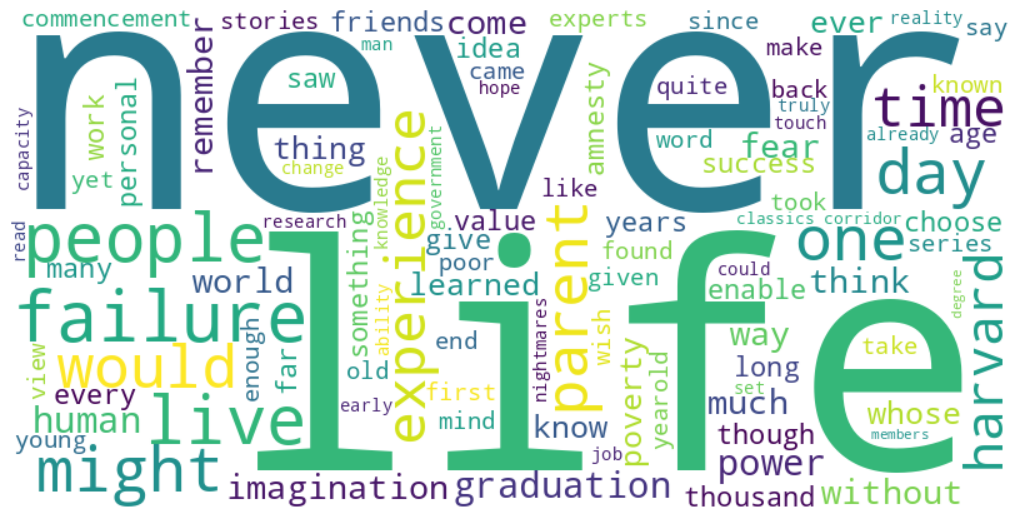

In [ ]:
# =========================================================
# 2.2 GENERACIÓN DE LA NUBE DE PALABRAS (WORDCLOUD)
# =========================================================

import re
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# 1. Leer el archivo con el discurso
with open("discurso_jk_rowling.txt", "r", encoding="utf-8") as archivo:
    texto_original = archivo.read()

# 2. Limpieza de caracteres extraños y conversión a minúsculas
# Nos quedamos únicamente con palabras (letras)
texto_limpio = re.sub(r'[^a-zA-Z\s]', '', texto_original)
texto_limpio = texto_limpio.lower()

# 3. Definir y configurar el objeto WordCloud con las stopwords en inglés
# Usamos las stopwords que ya descargamos de NLTK en el paso anterior
stopwords_ingles = stop_words

# Creamos la nube de palabras
nube_palabras = WordCloud(
    width=800,
    height=400,
    background_color="white",
    stopwords=stopwords_ingles,
    colormap="viridis",
    max_words=100
).generate(texto_limpio)

# 4. Mostrar la nube de palabras usando matplotlib
plt.figure(figsize=(10, 5), facecolor=None)
plt.imshow(nube_palabras, interpolation="bilinear")
plt.axis("off")
plt.tight_layout(pad=0)
plt.show()

### 2.3 Usando el texto que conseguiste en el punto 1).



#### 2.3.1 Limpia y preprocesa el texto, descomponelo en oraciones, arma una matriz documento-vocabulario.


In [ ]:
# =========================================================
# 2.3.1 LIMPIEZA, SEGMENTACIÓN Y MATRIZ DOCUMENTO-VOCABULARIO
# =========================================================

import nltk
from nltk.tokenize import sent_tokenize
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

# Asegurar que el recurso para separar oraciones esté descargado
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

# 1. Cargar el discurso
with open("discurso_jk_rowling.txt", "r", encoding="utf-8") as archivo:
    texto_completo = archivo.read()

# 2. Descomponer el discurso en oraciones
oraciones = sent_tokenize(texto_completo)
print(f"Total de oraciones (documentos) extraídas: {len(oraciones)}")

# 3. Armar la matriz Documento-Vocabulario (usando CountVectorizer)
# Configuramos para pasar a minúsculas y remover stop words en inglés
vectorizador = CountVectorizer(stop_words='english')
matriz_documento_vocabulario = vectorizador.fit_transform(oraciones)

# Convertir a un DataFrame de pandas para visualizar las primeras filas y columnas
vocabulario = vectorizer_features = vectorizador.get_feature_names_out()
df_matriz = pd.DataFrame(matriz_documento_vocabulario.toarray(), columns=vocabulario)

# Mostrar una vista previa de la matriz (primeras 5 oraciones y 10 palabras)
print("\nVista previa de la Matriz Documento-Vocabulario (primeras 5 filas x 10 columnas):")
print(df_matriz.iloc[:5, :10])

Total de oraciones (documentos) extraídas: 127

Vista previa de la Matriz Documento-Vocabulario (primeras 5 filas x 10 columnas):
   18  2008  20s  21  42  61st  abandon  ability  able  academic
0   0     0    0   0   0     0        0        0     0         0
1   0     0    0   0   0     0        0        0     0         0
2   0     0    0   0   0     0        0        0     0         0
3   0     0    0   0   0     0        0        0     0         0
4   0     0    0   0   0     0        0        0     0         0



#### 2.3.2 Determina la longitud de tu vocabulario.

In [ ]:
# =========================================================
# 2.3.2 DETERMINACIÓN DE LA LONGITUD DEL VOCABULARIO
# =========================================================

# Obtener la longitud del vocabulario desde el vectorizador anterior
longitud_vocabulario = len(vocabulario)

print(f"La longitud total del vocabulario (palabras únicas después de aplicar filtros) es: {longitud_vocabulario}")
print(f"La forma de la matriz documento-vocabulario es: {matriz_documento_vocabulario.shape} (Oraciones x Palabras)")

La longitud total del vocabulario (palabras únicas después de aplicar filtros) es: 858
La forma de la matriz documento-vocabulario es: (127, 858) (Oraciones x Palabras)



#### 2.3.3. Aplica TF-IDF a tu matriz documento-vocabulario

In [ ]:
# =========================================================
# 2.3.3 APLICACIÓN DE TF-IDF A LA MATRIZ DOCUMENTO-VOCABULARIO
# =========================================================

from sklearn.feature_extraction.text import TfidfTransformer
import pandas as pd

# 1. Inicializar el transformador TF-IDF
transformador_tfidf = TfidfTransformer()

# 2. Aplicar la transformación sobre nuestra matriz de conteo (frecuencias)
matriz_tfidf = transformador_tfidf.fit_transform(matriz_documento_vocabulario)

# 3. Convertir el resultado a un DataFrame de pandas para su análisis
df_tfidf = pd.DataFrame(matriz_tfidf.toarray(), columns=vocabulario)

# 4. Mostrar dimensiones y un ejemplo de las palabras con mejores puntuaciones TF-IDF promedio
print(f"Forma de la matriz TF-IDF: {df_tfidf.shape} (Oraciones x Palabras)\n")

# Calcular el valor promedio de TF-IDF de cada palabra para ver cuáles tienen mayor peso específico
palabras_relevantes = df_tfidf.mean().sort_values(ascending=False)

print("Top 15 palabras con mayor relevancia (promedio TF-IDF) en el discurso:")
print(palabras_relevantes.head(15))

Forma de la matriz TF-IDF: (127, 858) (Oraciones x Palabras)

Top 15 palabras con mayor relevancia (promedio TF-IDF) en el discurso:
failure       0.029505
life          0.023007
people        0.022569
day           0.019363
parents       0.015599
think         0.015500
harvard       0.015201
come          0.014680
poverty       0.014059
graduation    0.013919
live          0.012661
way           0.012436
power         0.012431
learned       0.011756
world         0.011734
dtype: float64




```
# Esto tiene formato de código, las palabras con mayor valor de indice son las mas usadas en el discurso
```

Explica el formato de tu matriz resultante: documentos, vocabulario, tamaño. Brinda tus conclusiones.

El análisis TF-IDF permitió identificar las palabras más representativas del discurso. Los términos con mayor relevancia fueron failure, life, people, parents, harvard y graduation, lo que indica que el texto se centra en experiencias personales, educación, crecimiento personal y aprendizaje a partir de los fracasos. Estos resultados permiten resumir las temáticas principales del discurso mediante técnicas de procesamiento de lenguaje natural.

# Conclusiones y Análisis del Formato de la Matriz

### 1. Formato de la Matriz Resultante
* **Documentos (Filas):** Contamos con **127 documentos**, donde cada documento corresponde a una oración individual extraída y segmentada del discurso de J.K. Rowling mediante el tokenizador de NLTK.
* **Vocabulario (Columnas):** Está compuesto por **858 términos únicos**. Este número representa todas las palabras con significado léxico que quedaron tras aplicar la limpieza (conversión a minúsculas, eliminación de caracteres especiales y filtrado de las stop words en inglés).
* **Tamaño y Forma:** La matriz resultante tiene una dimensión de **(127, 858)**. Es una matriz esparcida (sparse matrix), donde la gran mayoría de las celdas contienen valor cero (0.0), ya que una oración individual solo contiene un puñado de las 858 palabras del vocabulario general.

### 2. Análisis de Métricas (TF-IDF vs. Frecuencia Simple)
* La ponderación **TF-IDF** ha demostrado ser muy superior a la simple frecuencia. Mientras que la frecuencia bruta solo nos dice cuántas veces aparece una palabra, TF-IDF penaliza aquellas palabras comunes a lo largo de todo el texto y premia las palabras clave que definen la temática de oraciones específicas.
* Las tres palabras con mayor relevancia promedio según TF-IDF coinciden exactamente con los pilares del discurso de J.K. Rowling en Harvard:
  1. **failure (0.0295):** Refleja su enfoque sobre "los beneficios del fracaso".
  2. **life (0.0230):** Relacionado con la transición al umbral de la vida real.
  3. **people (0.0225):** Vinculado a sus experiencias de empatía en Amnistía Internacional.

### 3. Conclusiones Generales del Trabajo Práctico
* **Web Scraping:** El uso de `BeautifulSoup` y `requests` permitió automatizar la adquisición de un texto limpio directo de una fuente confiable en Internet (Harvard Gazette), demostrando ser un paso fundamental en la minería de datos.
* **Preprocesamiento del Lenguaje Natural (PLN):** Herramientas como NLTK facilitan enormemente tareas de normalización (tokenización y filtrado de stopwords). Sin este filtrado previo, la nube de palabras y las matrices habrían sido dominadas por conectores vacíos de significado (*the, a, and, of*).
* **Representación Vectorial:** La transformación del discurso a formatos numéricos mediante matrices de frecuencia y TF-IDF es la puerta de entrada indispensable para entrenar modelos más avanzados de Machine Learning, tales como clasificadores de texto, análisis de sentimiento o algoritmos de agrupamiento (Clustering).


# Anexo, código de ejemplo del uso de wordcloud

Instalar e importar la librería

In [ ]:
# instalar wordcloud
!pip install wordcloud


In [ ]:

# Importar librerías
from wordcloud import WordCloud
import matplotlib.pyplot as plt


In [ ]:

# Texto de ejemplo
text = "Este es un texto de ejemplo para crear una nube de palabras usando word cloud. Puedes reemplazar este texto utilizando tu propio texto."

# Crear un objeto WordCloud
wordcloud = WordCloud(width=800, height=400, background_color="white").generate(text)


Mostramos la imagen generada

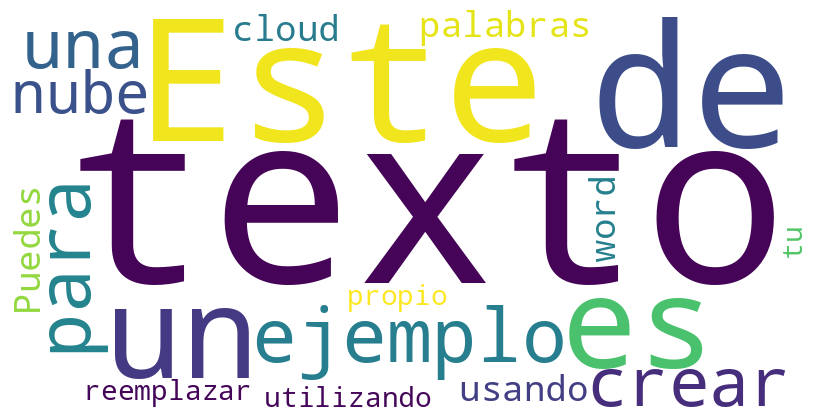

In [ ]:

# mostramos la imagen generada
plt.figure(figsize=(8, 8), facecolor=None)
plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad=0)
plt.show()

Modificamos el ejemplo anterior agregando palabras en español que no queremos que considere para crear la nube de palabras. Estas son las stop_words



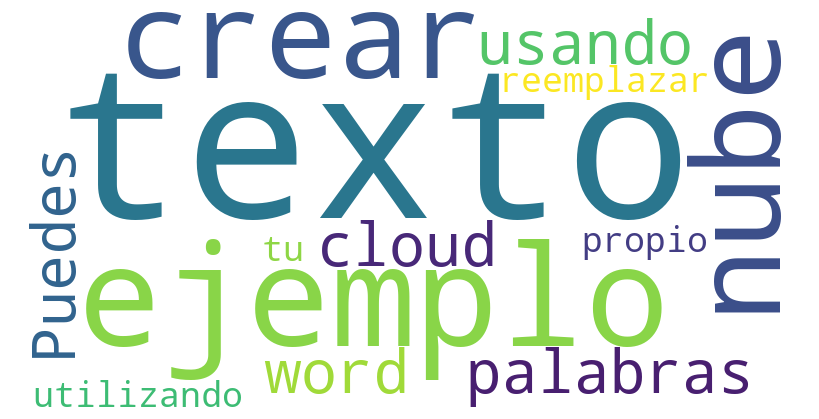

In [ ]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

# Texto de ejemplo
text = "Este es un texto de ejemplo para crear una nube de palabras usando word cloud. Puedes reemplazar este texto utilizando tu propio texto."

# Definir stopwords en español
stopwords_es = set(STOPWORDS)
stopwords_es.update(["con", "que", "los", "para", "un", "una", "el", "la", "en", "y", "o", "de", "a", "se", "es", "al", "como", "por", "no", "su", "más", "pero", "si", "este", "esta", "eso", "esa", "todo", "todos", "todas", "cada", "cual", "cualquier", "algo", "alguna", "algún", "ningún", "ninguna", "ninguno", "otro", "otros", "otras", "sobre", "entre", "durante", "desde", "hasta", "también", "así", "mismo", "misma", "mismo", "misma", "tan", "tanto", "tanta", "muy", "poco", "poca", "poco", "nada", "solo", "sola", "solo", "sola", "siempre", "nunca", "jamás", "casi", "aproximadamente", "cerca", "lejos", "antes", "después", "ahora", "hoy", "ayer", "mañana", "luego", "mientras", "mientras tanto", "después de", "antes de", "durante", "sin", "aunque", "a pesar de", "debido a", "gracias a", "por qué", "cómo", "dónde", "cuándo", "quién", "qué", "cuál"])

# Crear un objeto WordCloud con stopwords en español
wordcloud = WordCloud(width=800, height=400, background_color="white", stopwords=stopwords_es).generate(text)

# Mostramos la imagen generada
plt.figure(figsize=(8, 8), facecolor=None)
plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad=0)
plt.show()
